# Staleness over time

Reproduces the figure of the overdue share over time and the table that normalises staleness by size and removal effort (Section 4.2).

Input: one CSV per system and snapshot, produced by `../longitudinal/02-extract-snapshots.sh`. Run it first (see `../longitudinal/README.md`).

In [1]:
import collections
import datetime as dt
import json
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

SNAP = '../longitudinal/snapshots'
ASSETS = '../assets'
DATES = json.load(open(f'{SNAP}/dates.json'))

SYSTEMS = {'chromium': 'Chromium', 'gitlab': 'GitLab', 'kubernetes': 'Kubernetes', 'vespa': 'Vespa'}
LOC = {'chromium': 44.04, 'gitlab': 10.62, 'kubernetes': 4.96, 'vespa': 1.82}  # MLoC, Table 1
TOGGLES = {'chromium': 1896, 'gitlab': 407, 'kubernetes': 211, 'vespa': 145}  # Table 1, incl. permanent

# Kubernetes declares its gates in the format read by the extraction script only from v1.33 (April 2025)
WINDOW_START = '2025-04-01'


def read_csv(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False).to_dict('records')


def chromium_flags(label):
    return {r['flag_name']: {'expiry': int(r['expiry_milestone']) if r['expiry_milestone'] else None}
            for r in read_csv(f'{SNAP}/chromium/{label}.csv')}


def gitlab_flags(label):
    out = {}
    for r in read_csv(f'{SNAP}/gitlab/{label}.csv'):
        parts = r['definition_file'].split('/')
        i = parts.index('feature_flags')
        out[r['flag_name']] = {'type': parts[i + 1] if len(parts) > i + 2 else None,
                               'milestone': r['milestone'] or None}
    return out


def k8s_gates(label):
    return {r['gate_name'].split('.')[-1]: {'gate': r['gate_name'], 'stage': r['stage'] or None,
                                           'removal_version': r['removal_version'] or None,
                                           'has_expiration': r['has_expiration'] == 'true'}
            for r in read_csv(f'{SNAP}/kubernetes/{label}.csv')}


def vespa_flags(kind, sha):
    path = f'{SNAP}/vespa/{kind}/{sha}.csv'
    if not os.path.exists(path):
        return None
    if kind == 'permanent':
        return {r['flag_name']: {'expires': None} for r in read_csv(path)}
    return {r['flag_name']: {'expires': r['expires_at'] or None} for r in read_csv(path)}

## Helpers

Between two snapshots, a toggle is *removed* if it disappears, and *extended* if its deadline moves later. `episodes` follows each deadline until one of these happens or the last snapshot is reached.

In [2]:
GITLAB_MAX_MINOR = {10: 8, 11: 11, 12: 10, 13: 12, 14: 10, 15: 11, 16: 11, 17: 11, 18: 11, 19: 11, 20: 11}
LIFESPAN = {'gitlab_com_derisk': 2, 'wip': 4, 'beta': 6, 'experiment': 6}  # months, from the GitLab docs


def d(s):
    try:
        return dt.date.fromisoformat(s[:10])
    except ValueError:  # e.g. '2023-04-31' in Vespa's Flags.java
        y, m = int(s[:4]), int(s[5:7])
        return dt.date(y + (m == 12), m % 12 + 1, 1) - dt.timedelta(days=1)


def months(a, b):
    return (d(b) - d(a)).days / 30.44


def pct(a, b):
    return round(100 * a / b, 1) if b else 0.0


def gitlab_index(ms):
    """'major.minor' -> sequential milestone index, as in notebook 01."""
    try:
        major, minor = [int(x) for x in str(ms).split('.')[:2]]
    except (ValueError, TypeError):
        return None
    return sum(GITLAB_MAX_MINOR.get(m, 11) + 1 for m in range(min(GITLAB_MAX_MINOR), major)) + minor


def gitlab_status(flag, current):
    life = LIFESPAN.get(flag['type'])
    intro = gitlab_index(flag['milestone'])
    if life is None or intro is None:
        return 'none'
    deadline, cur = intro + life, gitlab_index(current)
    if cur > deadline:
        return 'expired'
    return 'soon' if cur >= deadline - 1 else 'active'


def k8s_num(v):
    """'1.36' -> 136, so that versions can be compared as numbers."""
    if not v:
        return None
    major, minor = [int(x) for x in str(v).lstrip('v').split('.')[:2]]
    return major * 100 + minor


def episodes(snaps, deadline_of, overdue):
    eps, open_eps = [], {}
    for i, s in enumerate(snaps):
        nxt = snaps[i + 1] if i + 1 < len(snaps) else None
        for name, f in s['flags'].items():
            dl = deadline_of(f)
            if name not in open_eps:
                if dl is None:
                    continue
                open_eps[name] = {'name': name, 'deadline': dl, 'start': s['date']}
            ep = open_eps[name]
            late = overdue(ep['deadline'], s)
            if nxt is None:
                ep['outcome'] = 'overdue at end' if late else 'pending'
                ep['end'] = s['date']
                eps.append(open_eps.pop(name))
                continue
            g = nxt['flags'].get(name)
            new = deadline_of(g) if g is not None else None
            if g is None:
                outcome = 'removed late' if late else 'removed on time'
            elif new is None:
                outcome = 'made permanent'
            elif new > ep['deadline']:
                outcome = 'extended late' if late else 'extended on time'
            else:
                continue
            ep.update(outcome=outcome, end=nxt['date'])
            eps.append(open_eps.pop(name))
            if g is not None and new is not None:
                open_eps[name] = {'name': name, 'deadline': new, 'start': nxt['date']}
    return eps


def removals_between(snaps, start, end):
    """Toggles removed between snapshots in [start, end]."""
    sel = [s for s in snaps if start <= s['date'] <= end]
    n = sum(len(set(a['flags']) - set(b['flags'])) for a, b in zip(sel, sel[1:]))
    return n, sel[0]['date'], sel[-1]['date']

## Per system

For each system: overdue counts at T0 and T1, the overdue share at every snapshot, and the removals and extensions in the year before T0.

**Chromium.** Snapshots: every milestone branch point since M80, plus T0 (M145) and T1 (M159). A flag is overdue if its `expiry_milestone` is below the current milestone.

In [3]:
def chromium_snapshots():
    snaps = []
    for f in os.listdir(f'{SNAP}/chromium'):
        label = f[:-4]
        cur = {'T0': 145, 'T1': 159}.get(label) or int(label[1:])
        snaps.append({'label': label, 'date': DATES[f'chromium:{label}'], 'cur': cur, 'flags': chromium_flags(label)})
    return sorted(snaps, key=lambda s: (s['date'], s['cur']))


def has_deadline_c(f):
    return f['expiry'] is not None and f['expiry'] != -1


def chromium_counts(s):
    dl = [f['expiry'] for f in s['flags'].values() if has_deadline_c(f)]
    return {'with_deadline': len(dl), 'overdue': sum(e < s['cur'] for e in dl)}


def chromium():
    snaps = chromium_snapshots()
    by = {s['label']: s for s in snaps}
    t0, t1 = by['T0'], by['T1']
    out = {'T0': chromium_counts(t0), 'T1': chromium_counts(t1)}
    eps = episodes(snaps, lambda f: f['expiry'] if has_deadline_c(f) else None, lambda dl, s: dl < s['cur'])
    start = (d(t0['date']) - dt.timedelta(days=365)).isoformat()
    base = max(s['date'] for s in snaps if s['date'] <= start)
    n, a, b = removals_between(snaps, base, t0['date'])
    out['removals_12m_before_T0'] = {'n': n, 'per_month': round(n / months(a, b), 1)}
    out['extensions_12m_before_T0'] = sum(1 for e in eps if e['outcome'].startswith('extended') and a <= e['end'] <= b)
    out['series'] = [(s['date'], pct(chromium_counts(s)['overdue'], chromium_counts(s)['with_deadline']))
                     for s in snaps if s['cur'] >= 90]
    return out

**GitLab.** Snapshots: monthly releases 17.0 to 19.5, plus T0 and T1. As in notebook 01, the deadline is the introduction milestone plus the documented lifespan of the flag type. GitLab has no extensions, since it has no explicit deadlines.

In [4]:
def gitlab_snapshots():
    tags = [f'v17.{m}.0-ee' for m in range(12)] + [f'v18.{m}.0-ee' for m in range(12)] + \
           [f'v19.{m}.0-ee' for m in range(6)]
    snaps = [{'label': t, 'date': DATES[f'gitlab:{t}'], 'cur': t[1:-5], 'flags': gitlab_flags(t)} for t in tags]
    for t, cur in (('T0', '18.10'), ('T1', '19.6')):
        snaps.append({'label': t, 'date': DATES[f'gitlab:{t}'], 'cur': cur, 'flags': gitlab_flags(t)})
    return sorted(snaps, key=lambda s: s['date'])


def gitlab_counts(s):
    c = collections.Counter(gitlab_status(f, s['cur']) for f in s['flags'].values())
    return {'with_deadline': c['expired'] + c['soon'] + c['active'], 'overdue': c['expired']}


def gitlab():
    snaps = gitlab_snapshots()
    by = {s['label']: s for s in snaps}
    t0, t1 = by['T0'], by['T1']
    out = {'T0': gitlab_counts(t0), 'T1': gitlab_counts(t1)}
    start = (d(t0['date']) - dt.timedelta(days=365)).isoformat()
    base = max(s['date'] for s in snaps if s['date'] <= start)
    n, a, b = removals_between(snaps, base, t0['date'])
    out['removals_12m_before_T0'] = {'n': n, 'per_month': round(n / months(a, b), 1)}
    out['series'] = [(s['date'], pct(gitlab_counts(s)['overdue'], gitlab_counts(s)['with_deadline'])) for s in snaps]
    return out

**Kubernetes.** Snapshots: v1.33 to v1.37, plus T0 and T1. A gate is overdue once its removal version has passed. The denominator is all gates with expiration information.

In [5]:
def k8s_snapshots():
    snaps = []
    for t in ('v1.33.0', 'v1.34.0', 'v1.35.0', 'v1.36.0', 'v1.37.0', 'T0', 'T1'):
        cur = {'T0': '1.36', 'T1': '1.38'}.get(t) or t[1:5]
        snaps.append({'label': t, 'date': DATES[f'kubernetes:{t}'], 'cur': k8s_num(cur), 'flags': k8s_gates(t)})
    return sorted(snaps, key=lambda s: (s['cur'], s['date']))


def rv(x):
    return k8s_num(x['removal_version'])


def k8s_counts(s):
    with_exp = [x for x in s['flags'].values() if x['has_expiration']]
    return {'with_deadline': len(with_exp),
            'overdue': sum(1 for x in with_exp if rv(x) is not None and rv(x) < s['cur'])}


def kubernetes():
    snaps = k8s_snapshots()
    by = {s['label']: s for s in snaps}
    t0, t1 = by['T0'], by['T1']
    out = {'T0': k8s_counts(t0), 'T1': k8s_counts(t1)}
    eps = episodes(snaps, lambda x: rv(x) if x['has_expiration'] else None, lambda dl, s: dl < s['cur'])
    # Only from v1.33 on, see WINDOW_START
    base = [s for s in snaps if s['label'] in ('v1.33.0', 'v1.34.0', 'T0')]
    n = sum(len(set(a['flags']) - set(b['flags'])) for a, b in zip(base, base[1:]))
    out['removals_12m_before_T0'] = {'n': n, 'per_month': round(n / months(base[0]['date'], t0['date']), 1)}
    out['extensions_12m_before_T0'] = sum(1 for e in eps if e['outcome'].startswith('extended')
                                          and base[0]['date'] < e['end'] <= t0['date'])
    out['series'] = [(s['date'], pct(k8s_counts(s)['overdue'], k8s_counts(s)['with_deadline'])) for s in snaps]
    return out

**Vespa.** We have every commit that touched `Flags.java`, so events have exact dates and the share is sampled weekly. A flag is removed when it leaves `Flags.java` without showing up in `PermanentFlags.java`.

In [6]:
def vespa_versions(kind):
    commits = json.load(open(f'{SNAP}/vespa/{kind}-commits.json'))
    out = []
    for c in sorted(commits, key=lambda c: c['date']):
        flags = vespa_flags(kind, c['sha'])
        if flags is not None:
            out.append({'date': c['date'][:10], 'flags': flags})
    return out


def vespa_counts(s):
    dl = [f['expires'] for f in s['flags'].values() if f['expires']]
    return {'with_deadline': len(dl), 'overdue': sum(e < s['date'] for e in dl)}


def vespa():
    vers = vespa_versions('flags')
    first_perm = {}
    for v in vespa_versions('permanent'):
        for n in v['flags']:
            first_perm.setdefault(n, v['date'])
    t0 = {'date': '2025-12-22', 'flags': vespa_flags('flags', 'f2f0d37afd1d889e33a12f82fbf58809dbdef391')}
    t1 = {'date': '2026-10-31', 'flags': vespa_flags('flags', '44bcb9564ac1b35512b53a41c4c97880299aa5f1')}
    out = {'T0': vespa_counts(t0), 'T1': vespa_counts(t1)}

    # Running max of the deadline, to ignore commits from older branches
    last_seen, maxdl, events = {}, {}, []
    for i, v in enumerate(vers):
        for n, f in v['flags'].items():
            last_seen[n] = i
            e = f['expires']
            if not e:
                continue
            if n in maxdl and e > maxdl[n]:
                events.append({'type': 'extended', 'date': v['date']})
            if n not in maxdl or e > maxdl[n]:
                maxdl[n] = e
    for n, i in last_seen.items():
        if i == len(vers) - 1 or n not in maxdl:
            continue
        rdate = vers[i + 1]['date']
        # Moved to PermanentFlags.java, not removed
        moved = n in first_perm and first_perm[n] >= (d(rdate) - dt.timedelta(days=60)).isoformat()
        events.append({'type': 'made permanent' if moved else 'removed', 'date': rdate})

    yr = [e for e in events if (d(t0['date']) - dt.timedelta(days=365)).isoformat() <= e['date'] <= t0['date']]
    removed = sum(e['type'] == 'removed' for e in yr)
    out['removals_12m_before_T0'] = {'n': removed, 'per_month': round(removed / 12, 1)}
    out['extensions_12m_before_T0'] = sum(e['type'] == 'extended' for e in yr)

    # Weekly samples, counted from the first version whose flags carry dates
    first_dated = next(v['date'] for v in vers if sum(1 for f in v['flags'].values() if f['expires']) > 5)
    series, day, idx = [], d(first_dated), 0
    while day <= d(t1['date']):
        while idx + 1 < len(vers) and d(vers[idx + 1]['date']) <= day:
            idx += 1
        c = vespa_counts({'date': day.isoformat(), 'flags': vers[idx]['flags']})
        series.append((day.isoformat(), pct(c['overdue'], c['with_deadline'])))
        day += dt.timedelta(days=7)
    out['series'] = series
    return out

In [7]:
res = {'chromium': chromium(), 'gitlab': gitlab(), 'kubernetes': kubernetes(), 'vespa': vespa()}

## Overdue share over time

Share of toggles with a deadline that are past it, from April 2025 to T1. Stars mark T0, diamonds T1. GitLab values are estimates, since GitLab has no explicit deadlines. Saved to `../assets/staleness-over-time.{pdf,png}`.

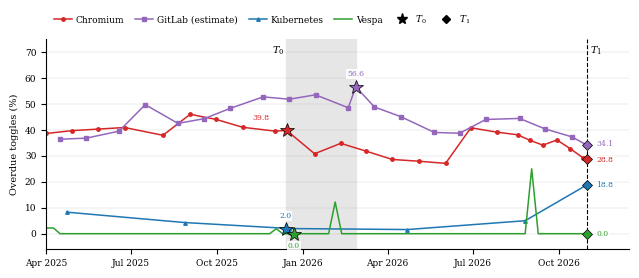

In [8]:
from matplotlib.lines import Line2D


def share(c):
    return pct(c['overdue'], c['with_deadline'])


plt.rcParams.update({'font.family': 'serif', 'font.size': 7, 'axes.labelsize': 7, 'pdf.fonttype': 42,
                     'legend.fontsize': 6.5, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5,
                     'mathtext.fontset': 'dejavuserif'})
fig, ax = plt.subplots(figsize=(6.4, 2.8))
style = {'chromium': ('Chromium', '#d62728', 'o'), 'gitlab': ('GitLab (estimate)', '#9467bd', 's'),
         'kubernetes': ('Kubernetes', '#1f77b4', '^'), 'vespa': ('Vespa', '#2ca02c', None)}
# Offsets (points) of the value labels at T0 and T1, so that they do not overlap
t0_off = {'chromium': (-12, 9), 'gitlab': (0, 9), 'kubernetes': (0, 9), 'vespa': (0, -9)}
t1_off = {'chromium': (7, -1), 'gitlab': (7, 1), 'kubernetes': (7, 0), 'vespa': (7, 0)}
t0_dates = [dt.datetime.fromisoformat(DATES[f'{s}:T0']) for s in style]
ax.axvspan(min(t0_dates), max(t0_dates), color='#e6e6e6', zorder=0)
ax.text(min(t0_dates), 73, r'$T_0$ ', ha='right', va='top', fontsize=7)
t1 = dt.datetime.fromisoformat(DATES['chromium:T1'])
ax.axvline(t1, color='black', linestyle='--', linewidth=0.8, zorder=0)
ax.text(t1, 73, r' $T_1$', ha='left', va='top', fontsize=7)
for s, (name, col, mk) in style.items():
    pts = [p for p in res[s]['series'] if p[0] >= WINDOW_START]
    ax.plot([dt.datetime.fromisoformat(p[0]) for p in pts], [p[1] for p in pts],
            color=col, marker=mk, markersize=2.5, linewidth=1.1, label=name, zorder=2)
    for snap, mark, size, off in (('T0', '*', 10, t0_off[s]), ('T1', 'D', 5.5, t1_off[s])):
        x, y = dt.datetime.fromisoformat(DATES[f'{s}:{snap}']), share(res[s][snap])
        ax.plot([x], [y], marker=mark, color=col, markersize=size, markeredgecolor='black',
                markeredgewidth=0.5, linestyle='none', zorder=3)
        ax.annotate(f'{y:.1f}', (x, y), xytext=off, textcoords='offset points', fontsize=5.5, color=col,
                    ha='left' if off[0] > 0 else ('right' if off[0] < 0 else 'center'), va='center',
                    bbox=dict(boxstyle='square,pad=0.1', facecolor='white', edgecolor='none', alpha=0.85),
                    zorder=4)
ax.set_ylabel('Overdue toggles (%)')
ax.set_ylim(-6, 75)
ax.set_xlim(dt.datetime.fromisoformat(WINDOW_START), dt.datetime(2026, 12, 15))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 4, 7, 10)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.grid(axis='y', linewidth=0.3, alpha=0.6)
handles = ax.get_legend_handles_labels()[0] + [
    Line2D([], [], marker='*', color='black', markersize=8, linestyle='none', label=r'$T_0$'),
    Line2D([], [], marker='D', color='black', markersize=4.5, linestyle='none', label=r'$T_1$')]
ax.legend(handles=handles, loc='upper left', ncol=6, frameon=False, bbox_to_anchor=(0, 1.16),
          columnspacing=1.2, handletextpad=0.4)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(f'{ASSETS}/staleness-over-time.pdf', bbox_inches='tight')
fig.savefig(f'{ASSETS}/staleness-over-time.png', dpi=300, bbox_inches='tight')
plt.show()

## Normalised staleness (Table 3)

Overdue toggles at T0 per MLoC, and the backlog: how many months of its usual removals (in the year before T0) a system would need to clear them. Extensions are deadlines moved later in that same year.

In [9]:
rows = []
for key, name in SYSTEMS.items():
    r = res[key]
    over, per_month = r['T0']['overdue'], r['removals_12m_before_T0']['per_month']
    t1 = r['T1']
    rows.append({'System': name,
                 'Toggles per MLoC': round(TOGGLES[key] / LOC[key], 1),
                 'Overdue per MLoC': round(over / LOC[key], 1),
                 'Removed per month': per_month,
                 'Extensions': r.get('extensions_12m_before_T0', '–'),
                 'Backlog (months)': round(over / per_month, 1) if per_month else None,
                 'Overdue at T1': f"{t1['overdue']} / {t1['with_deadline']:,} ({share(t1):.1f}%)"})
pd.DataFrame(rows).set_index('System')

,Toggles per MLoC,Overdue per MLoC,Removed per month,Extensions,Backlog (months),Overdue at T1
System,,,,,,
Chromium,43.1,15.8,61.6,836,11.3,"480 / 1,666 (28.8%)"
GitLab,38.3,10.5,37.4,–,3.0,154 / 452 (34.1%)
Kubernetes,42.5,0.2,2.0,1,0.5,9 / 48 (18.8%)
Vespa,79.7,0.0,3.2,266,0.0,0 / 32 (0.0%)
